[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_01/MFM_ch1_overnight_returns/MFM_ch1_overnight_returns.ipynb)

# MFM_ch1_overnight_returns

Case study 2, Bondarenko and Muravyev (2023, *Journal of Financial and Quantitative Analysis*), [Market return around the clock: a puzzle](https://doi.org/10.1017/S0022109022000783): on E-mini S&P 500 futures, the 4 hours around the European open account for the entire average market return. Course replication on daily SPY prices, 1993-2026: overnight (close to next open), intraday (open to close) and dividend components of the total log return; annualised means, volatilities, Sharpe ratios and t statistics with the Newey-West (heteroskedasticity and autocorrelation consistent, HAC) standard error, full sample and three subperiods; extension to Bitcoin 5-minute bars, US regular session against the rest of the day.

*Modelling Financial Markets (MFM), Chapter 1: Stylised Facts and Returns. Author: Daniel Traian Pele.*

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your Bucharest University of Economic Studies (ASE) Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (comma-separated values (CSV), charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [1]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_1'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))

Save your outputs to: /Users/danpele/Documents/2026 MFM/MFM/Quantlets/Ch_01/MFM_ch1_overnight_returns


In [2]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

## Data

Daily SPY prices (open, close, dividend-adjusted close) and Bitcoin 5-minute bars from the course repository (`data/market`).

In [3]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# local copy of the course data, if the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def market_path(fname):
    p = os.path.join(MARKET_DIR, fname) if MARKET_DIR else ''
    return p if p and os.path.exists(p) else REPO_RAW + fname


def read_market(symbol):
    """Daily OHLC file of the course data, indexed by date."""
    df = pd.read_csv(market_path(f'{symbol}.csv'), parse_dates=['date']).set_index('date').sort_index()
    df.index.name = 'Date'
    return df


spy = read_market('SPY.US')
print('SPY', spy.index[0].date(), '->', spy.index[-1].date(), len(spy), 'days')

SPY 1993-01-29 -> 2026-09-18 8467 days


## Style and helpers

In [4]:
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

MainBlue = '#1A3A6E'
IDAred = '#CD0000'
Forest = '#2E7D32'
Amber = '#B5853F'
Navy = '#1F2A44'

MainBlue = '#1A3A6E'
IDAred = '#CD0000'
Forest = '#2E7D32'
Amber = '#B5853F'
Navy = '#1F2A44'

SUBPERIODS = [('1993', '2004'), ('2005', '2015'), ('2016', '2026')]
US_SESSION = (9 * 60 + 30, 16 * 60)        # 09:30-16:00 New York time (US regular session)


def save_fig(name):
    plt.savefig(os.path.join(OUT_DIR, f'{name}.pdf'), bbox_inches='tight', transparent=True)
    plt.savefig(os.path.join(OUT_DIR, f'{name}.png'), bbox_inches='tight', transparent=True, dpi=180)
    plt.show()

## Analysis

In [5]:
def nw_se(x):
    """Standard error of the mean with the Newey-West long-run variance (Bartlett, L = floor(4 (T/100)^(2/9)))."""
    x = np.asarray(x, float)
    T = len(x)
    u = x - x.mean()
    L = int(np.floor(4 * (T / 100) ** (2 / 9)))
    lrv = u @ u / T
    for k in range(1, L + 1):
        lrv += 2 * (1 - k / (L + 1)) * (u[k:] @ u[:-k]) / T
    return np.sqrt(lrv / T)


def spy_split():
    """Daily overnight, intraday and dividend log returns of SPY."""
    s = read_market('SPY.US')
    f = s['adjusted_close'] / s['close']
    d = pd.DataFrame({'overnight': np.log(s['open'] / s['close'].shift(1)),
                      'intraday': np.log(s['close'] / s['open']),
                      'dividend': np.log(f / f.shift(1))}).dropna()
    d['total'] = d.sum(axis=1)
    return d


def stats_of(x, periods=252):
    x = np.asarray(x, float)
    se = nw_se(x)
    return {'n': int(len(x)), 'mean_bp': 1e4 * x.mean(), 'ann_mean_pct': 100 * periods * x.mean(),
            'ann_vol_pct': 100 * x.std(ddof=1) * np.sqrt(periods),
            'sharpe': x.mean() / x.std(ddof=1) * np.sqrt(periods), 't_nw': x.mean() / se,
            'ci95_ann_pct': [100 * periods * (x.mean() - 1.96 * se), 100 * periods * (x.mean() + 1.96 * se)]}


def btc_sessions():
    """Bitcoin, 5-minute bars: daily (New York calendar day) log return inside and outside 09:30-16:00 New York."""
    b = pd.read_csv(market_path('intraday/BTC-USD.CC_5m.csv'),
                    parse_dates=['datetime_utc']).set_index('datetime_utc')
    r = np.log(b['close']).diff().dropna()
    ny = r.index.tz_localize('UTC').tz_convert('America/New_York')
    start = ny.hour * 60 + ny.minute                          # each bar is labelled by its open time
    us = (start >= US_SESSION[0]) & (start < US_SESSION[1]) & (ny.dayofweek < 5)
    d = pd.DataFrame({'r': r.values, 'us': us, 'day': ny.date})
    dd = d.groupby(['day', 'us'])['r'].sum().unstack().fillna(0.0)    # weekends: no US session, return 0 there
    out = {'start': str(r.index[0].date()), 'end': str(r.index[-1].date()), 'days': int(len(dd)),
           'bars': int(len(r))}
    for key, col in [('us_session', True), ('outside', False)]:
        out[key] = stats_of(dd[col].values, periods=365)
    return out


def analyse():
    d = spy_split()
    res = {'start': str(d.index[0].date()), 'end': str(d.index[-1].date()), 'n': int(len(d)),
           'full': {k: stats_of(d[k]) for k in ['overnight', 'intraday', 'dividend', 'total']},
           'cum_log': {k: float(d[k].sum()) for k in ['overnight', 'intraday', 'dividend', 'total']},
           'overnight_share_price': float(d['overnight'].sum() / (d['overnight'] + d['intraday']).sum()),
           'subperiods': []}
    yr = d.groupby(d.index.year)[['overnight', 'intraday']].sum()
    res['years'] = int(len(yr))
    res['years_overnight_gt_intraday'] = int((yr['overnight'] > yr['intraday']).sum())
    res['years_overnight_pos'] = int((yr['overnight'] > 0).sum())
    res['years_intraday_pos'] = int((yr['intraday'] > 0).sum())
    for a, b in SUBPERIODS:
        x = d.loc[a:b]
        res['subperiods'].append({'from': a, 'to': b, 'overnight': stats_of(x['overnight']),
                                  'intraday': stats_of(x['intraday'])})
    res['corr_overnight_intraday'] = float(d['overnight'].corr(d['intraday']))
    res['btc'] = btc_sessions()
    return d, res


def fig_cs_overnight(d, res):
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(7.6, 3.0), gridspec_kw={'width_ratios': [1.65, 1]})
    c = d.cumsum()
    ax.plot(c.index, 100 * c['total'], color=MainBlue, lw=0.9, label='Close to close, with dividends')
    ax.plot(c.index, 100 * c['overnight'], color=IDAred, lw=0.9, label='Overnight: close to next open')
    ax.plot(c.index, 100 * c['intraday'], color=Forest, lw=0.9, label='Intraday: open to close')
    ax.plot(c.index, 100 * c['dividend'], color=Amber, lw=0.9, label='Dividends')
    ax.axhline(0, color=Navy, lw=0.5, ls='--')
    ax.set_xlim(c.index[0], c.index[-1])
    ax.set_ylabel('Cumulative log return (%)')
    ax.set_title(f"SPY, {res['start'][:4]}-{res['end'][:4]}: cumulative log returns")
    labels = [f'{p["from"]}-{p["to"][2:]}' for p in res['subperiods']] + ['Full sample']
    on = [p['overnight'] for p in res['subperiods']] + [res['full']['overnight']]
    idd = [p['intraday'] for p in res['subperiods']] + [res['full']['intraday']]
    x = np.arange(len(labels))
    w = 0.38
    for off, vals, col in [(-w / 2, on, IDAred), (w / 2, idd, Forest)]:
        m = np.array([v['ann_mean_pct'] for v in vals])
        lo = m - np.array([v['ci95_ann_pct'][0] for v in vals])
        hi = np.array([v['ci95_ann_pct'][1] for v in vals]) - m
        ax2.bar(x + off, m, w, color=col, alpha=0.85)
        ax2.errorbar(x + off, m, yerr=[lo, hi], fmt='none', ecolor=Navy, elinewidth=0.7, capsize=2)
    ax2.axhline(0, color=Navy, lw=0.5)
    ax2.set_xticks(x)
    ax2.set_xticklabels(labels)
    ax2.set_ylabel('Annualised mean (%)')
    ax2.set_title('Mean, 95% Newey-West interval')
    h, l = ax.get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=4, frameon=False)
    plt.tight_layout()
    save_fig('ch1_cs_overnight')

## Run

           ann_mean_pct  ann_vol_pct  sharpe   t_nw
overnight          7.73        10.63    0.73   4.61
intraday           0.76        15.19    0.05   0.33
dividend           1.79         0.91    1.96  12.34
total             10.28        18.53    0.55   3.70
1993 2004 {'overnight': (np.float64(10.86), np.float64(4.29)), 'intraday': (np.float64(-2.37), np.float64(-0.56))}
2005 2015 {'overnight': (np.float64(4.6), np.float64(1.74)), 'intraday': (np.float64(0.16), np.float64(0.04))}
2016 2026 {'overnight': (np.float64(7.45), np.float64(2.13)), 'intraday': (np.float64(4.88), np.float64(1.38))}
Bitcoin {'us_session': (np.float64(-3.6), np.float64(-0.18)), 'outside': (np.float64(20.9), np.float64(1.01))}


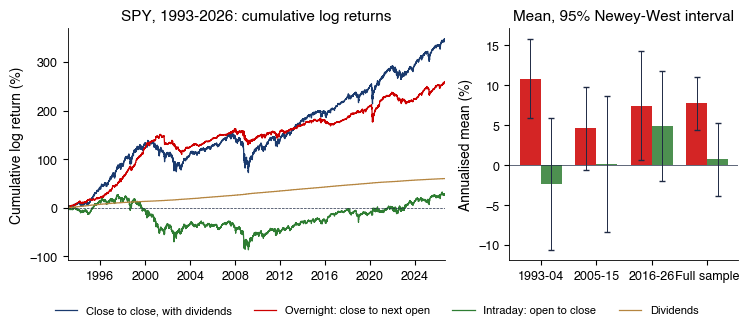

In [6]:
d, res = analyse()
with open(os.path.join(OUT_DIR, 'ch1_overnight.json'), 'w') as f:
    json.dump(res, f, indent=1)
rows = {k: res['full'][k] for k in ['overnight', 'intraday', 'dividend', 'total']}
print(pd.DataFrame(rows).T[['ann_mean_pct', 'ann_vol_pct', 'sharpe', 't_nw']].astype(float).round(2))
for p in res['subperiods']:
    print(p['from'], p['to'], {k: (round(p[k]['ann_mean_pct'], 2), round(p[k]['t_nw'], 2)) for k in ['overnight', 'intraday']})
print('Bitcoin', {k: (round(res['btc'][k]['ann_mean_pct'], 1), round(res['btc'][k]['t_nw'], 2)) for k in ['us_session', 'outside']})
fig_cs_overnight(d, res)

![ch1_cs_overnight](./ch1_cs_overnight.png)

Output: `ch1_cs_overnight.pdf`, `ch1_overnight.json`